(lineage_recorders)=

# Lineage recorders

Cut the reconstructed cell phylogeny of a mouse embryo into clones every half day from embryonic day 5.0 (E5.0) to E7.0, and measure at each cut which cell types share clones more often than chance. The embryo, E7.5-R1, was collected at E7.5 and profiled by single-cell RNA sequencing, and 1,032 of its 1,342 cells carry the PEtracer lineage recorder [@Koblan_2025], whose edits @Colgan_2026 used to build two clone trees. At E5.0 the clones of two or more cells span five cell types on average, and no pair of types stands out. By E6.5 those clones span 1.7 cell types on average, and two pairs share clones far more often than shuffled cell types would: the extraembryonic mesoderm with the hematoendothelial progenitors, 3.9 standard deviations above the mean of the shuffles, and the epiblast with the primitive streak, 3.6 above it. The cell types of each pair still shared ancestors alive at E6.5.

A lineage recorder writes heritable edits into target sites of the genome as cells divide, so the edits that cells share record their common ancestors. Tree builders reconstruct a phylogeny from the edits: a tree whose leaves are the sampled cells and whose internal nodes are their ancestors. Cutting the tree at a time groups the cells into clones, the descendants of each lineage alive at that time, and cell types that share clones descend from common ancestors. PEtracer's prime editor writes one of eight five-base insertions, the lineage marks, into the three sites of each integrated copy of its target cassette. The embryo is a chimera: its donor cells descend from injected stem cells that carry the recorder, and its host cells carry none.

This page is one of four on clonal analysis with `ds.clones`, and here the clones come from trees that a recorder's edits reconstruct. [Lineage tracing](lineage_tracing.ipynb) follows clones that lentiviral LARRY barcodes mark in mouse hematopoiesis over days 2, 4 and 6, [mitochondrial lineage tracing](mitochondrial_lineage_tracing.ipynb) calls clones in a human tumor from somatic mitochondrial DNA variants, and the [immune repertoires](immune_repertoires.ipynb) page groups T and B cells into clonotypes by their receptor chains. Each cut is saved in the store as an {term}`artifact`, a result recorded with its inputs and parameters, so the clone summaries of `ds.clones`, from clone sizes to coupling, read the clones of a cut like those of the other three pages.

## Download the embryo

GEO series [GSE342226](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE342226) holds embryo E7.5-R1 in two samples: GSM9925879, its expression matrix, and GSM9925880, its character matrix of each cell's marks and the two trees that the authors reconstructed. The authors also released the data under the MIT License as the Mouse Embryonic Lineage Atlas on [Zenodo](https://zenodo.org/records/23088914), with a table of their cell annotation. That table covers every embryo of the atlas and lists the donor cells of E7.5-R1 first, so an HTTP range request downloads only its header and those rows, 0.186 MB. The downloads take 34 MB together. The downloads and the store go to a temporary directory; use a project directory to keep them.

In [1]:
import hashlib
import shutil
import time
from http.client import HTTPException
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd

import cytearc
from cytearc.plotting import CellField, theme_context

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep the downloads and the store in a temporary directory; set output_dir to
# a project directory to keep them.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-12T17:19:11.164450Z | Wall time: 2.890 s

In [2]:
# Pin each file so that a changed download cannot alter the example silently.
# Name the files as the authors name the embryo and its two trees, since the
# import names each tree after its file.
geo = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9925nnn"
sources = {
    "E7.5-R1_matrix.mtx.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_matrix.mtx.gz",
        "d246178e0c6e045b735ac36770ecdbe73cbbdc1628b2b48945f7050e959d33a8",
    ),
    "E7.5-R1_features.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_features.tsv.gz",
        "28ab91827cb07d8ba9071ebe98101ade7a0f7a3f8f7d48b28c8e1f807f062c70",
    ),
    "E7.5-R1_barcodes.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_barcodes.tsv.gz",
        "47d445ff2cf5944ab66dfda8f0db3d5e91690d29c086de0a7c0a957b3309de66",
    ),
    "E7.5-R1_characters.csv.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_characters.csv.gz",
        "166131c571ca30338435d25bd3f437512e44c79a5d428953fe72d04bb4385e85",
    ),
    "E7.5-R1-C1.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C1.nwk.gz",
        "85e822845ca9774c9ca060375ea177f4b96a8b3994d00d297b1de15f6746714d",
    ),
    "E7.5-R1-C2.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C2.nwk.gz",
        "37f008640400fcee2b15d2988ce64c856d1d0e017229fff71d86a125773b562d",
    ),
    "E7.5-R1_donor_cells.csv": (
        "https://zenodo.org/records/23088914/files/E7.5-E10_cells.csv",
        "f96960f5f78f2d15321ef6acf3eecb546a0dc1f3a8aa074472212a3c13a4e341",
    ),
}

# Read only the header and the donor rows of E7.5-R1 from the atlas's cell table.
byte_ranges = {"E7.5-R1_donor_cells.csv": "bytes=0-185932"}


# Copy a file in blocks without holding it in memory, and refuse a whole table
# sent in place of the bytes requested. GEO's server times out when it is busy,
# so try a failed download again after a pause that grows with each attempt.
def download(url: str, path: Path, byte_range: str | None, attempts: int = 4) -> None:
    headers = {} if byte_range is None else {"Range": byte_range}
    for attempt in range(1, attempts + 1):
        try:
            with urlopen(Request(url, headers=headers), timeout=60) as response:
                if byte_range is not None and response.status != 206:
                    raise ValueError(f"{url} was sent whole, not the bytes requested")
                with path.open("wb") as target:
                    shutil.copyfileobj(response, target)
            return
        except (OSError, HTTPException) as error:
            failure = error
        if attempt < attempts:
            time.sleep(30 * attempt)
    raise ConnectionError(
        f"Could not download {url} in {attempts} attempts; last error: {failure}"
    )


# Download each file, and reject one whose contents differ from the verified source.
paths = {}
for name, (url, expected_digest) in sources.items():
    path = output_dir / name
    download(url, path, byte_ranges.get(name))
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each download and their total.
sizes = pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
)
sizes["Total"] = sizes.sum()
sizes.round(3)

E7.5-R1_matrix.mtx.gz        33.505
E7.5-R1_features.tsv.gz       0.637
E7.5-R1_barcodes.tsv.gz       0.008
E7.5-R1_characters.csv.gz     0.027
E7.5-R1-C1.nwk.gz             0.017
E7.5-R1-C2.nwk.gz             0.004
E7.5-R1_donor_cells.csv       0.186
Total                        34.384
Name: Downloaded MB, dtype: float64

Started: 2026-11-12T17:19:14.056924Z | Wall time: 1.700 s

## Build the expression store

The expression matrix holds the UMI counts of 78,258 genes in the 1,342 cells that the authors kept, donor and host. The store built from it holds the cells to which the marks, trees and clones below attach.

In [3]:
# Pair the matrix with its gene and cell files, and write them into a new store.
(candidate,) = cytearc.inspect_mtx(str(paths["E7.5-R1_matrix.mtx.gz"]))
store_path = output_dir / "E7.5-R1.zarr"
cytearc.MtxToZarr(cytearc.MtxReader(candidate), zarr_loc=str(store_path)).dump()

# Open the store, with its RNA assay as the default.
ds = cytearc.DataStore(str(store_path), default_assay="RNA")
ds

DataStore has 1342 (1342) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo'
   RNA assay has 78258 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'nCells'

Started: 2026-11-12T17:19:15.759833Z | Wall time: 14.816 s

The authors annotated the donor cells only. Label each donor cell with its cell type and each host cell as `host`, in a `cell_type` column that later steps group the cells by.

In [4]:
# Read the authors' annotation, and check that it names this embryo's donor cells.
annotation = pd.read_csv(paths["E7.5-R1_donor_cells.csv"], index_col=0)
cell_ids = pd.Index(ds.cells.fetch_all("ids"))
if not (
    annotation["embryo"].eq("E7.5-R1").all()
    and annotation["type"].eq("donor").all()
    and annotation.index.isin(cell_ids).all()
):
    raise ValueError("The annotation names cells outside this embryo's donor cells")

# Label each donor cell with its type, and every cell that the annotation leaves
# out as host.
cell_types = annotation["cell_type"].reindex(cell_ids, fill_value="host")
ds.cells.insert("cell_type", cell_types, overwrite=True)

# Count the cells of each type.
cell_types.value_counts().rename("Cells").rename_axis("Cell type").to_frame()

,Cells
Cell type,
Nascent mesoderm,325
host,310
Rostral ectoderm,215
Epiblast,175
Extraembryonic mesoderm,134
Primitive streak,91
Definitive endoderm,39
Hematoendothelial progenitor,32
Notochord,17


Started: 2026-11-12T17:19:30.579929Z | Wall time: 0.059 s

The donor cells fall into 10 cell types, from 325 cells of nascent mesoderm to a single prechordal plate cell, beside 310 host cells. Place the cell types on a UMAP with the RNA recipe, `ds.pipeline.rna`, which selects variable genes, normalizes them, reduces them with PCA, then embeds and clusters the cells. The recipe returns a {term}`pipeline run <PipelineRun>`, the saved record of its steps, and `run["umap"]` is the UMAP that the run saved. The authors already filtered these cells, so `filtering=False` keeps all of them.

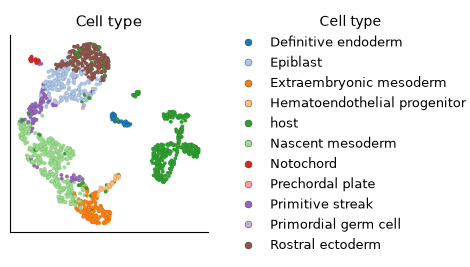

Started: 2026-11-12T17:19:30.643951Z | Wall time: 137.752 s

In [5]:
# Embed every cell with the RNA recipe, keeping the cells that the authors kept.
run = ds.pipeline.rna(label="rna", filtering=False)

# Locate the cell types on the UMAP.
ds.plots.embedding(
    layout=run["umap"], color_by=CellField("cell_type", label="Cell type")
)

The UMAP places the epiblast between the rostral ectoderm and the primitive streak, and the primitive streak leads through the nascent mesoderm to the extraembryonic mesoderm and the hematoendothelial progenitors, in the order in which gastrulation produces these cell types. Most host cells, which the annotation leaves untyped, form a group of their own. The clone trees below show which of these cell types also share ancestors.

## Read the character matrix

PEtracer's character matrix holds one row per cell and one column per site. Each column is named by its integration (one integrated copy of the cassette) and its site (EMX1, HEK3 or RNF2, the cassette's three target sites), as in `intID250-EMX1`. An entry is `*` for an unedited site, `1` to `8` for a lineage mark, `!` for an unknown mark (an insertion other than the eight marks) and `-` for a site that was not read. `clones.import_alleles` recognizes the format and joins each row to the cell of the same ID. The import takes the cells as a frozen cell selection, a saved list of cells that the imported alleles record as the cells they were joined to. `ds.snapshot_cell_selection("I")` freezes the cells of the {term}`cell key` `I`, here every cell of the store.

In [6]:
# Read the marks of every cell.
cells = ds.snapshot_cell_selection("I")
alleles = ds.clones.import_alleles(
    paths["E7.5-R1_characters.csv.gz"], cell_selection=cells
)

# Compare the donor and host cells by the integrations read and the sites edited.
allele_cells = ds.clones.load_alleles(alleles).cells[["n_integrations", "n_edits"]]
origin = cell_types.eq("host").map({True: "Host", False: "Donor"}).rename("Origin")
allele_cells.groupby(origin).agg(["min", "median", "max"])

n_integrations            n_edits           
                  min median max     min median max
Origin                                             
Donor              29   33.0  33      34   47.0  64
Host                0    0.0   0       0    0.0   0

Started: 2026-11-12T17:21:48.400211Z | Wall time: 0.680 s

Each donor cell reads 29 to 33 of the 33 integrations and holds an edit at 34 to 64 of the 99 sites, while the host cells, which carry no recorder, read none. The sites differ in how many of the cells that read them carry an edit.

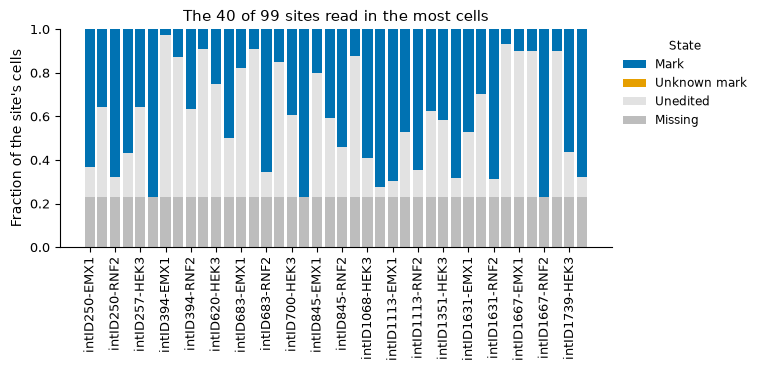

Started: 2026-11-12T17:21:49.084829Z | Wall time: 0.685 s

In [7]:
# Draw the share of cells in each state at the 40 sites read in the most cells.
ds.plots.recorder_states(alleles)

In [8]:
# Compare EMX1, HEK3 and RNF2 by the share of the cells reading each site that
# carry an edit there.
states = (
    ds.clones.load_alleles(alleles)
    .site_states()
    .pivot_table(
        index=["integration", "site"], columns="state", values="n_cells", observed=True
    )
)
edited = states["mark"] + states["unknown_mark"]
(edited / (edited + states["unedited"])).groupby(level="site").describe()[
    ["min", "50%", "max"]
].round(2)

,min,50%,max
site,,,
EMX1,0.00,0.23,0.91
HEK3,0.00,0.43,1.00
RNF2,0.04,0.84,1.00


Started: 2026-11-12T17:21:49.772524Z | Wall time: 0.136 s

The cassette's three sites fill at different rates: the median RNF2 site is edited in 84% of the cells that read it, the median HEK3 site in 43% and the median EMX1 site in 23%. A fast site is mostly edited within the first divisions, so its marks separate the early lineages, while a slow site keeps unedited copies that later divisions can still mark; together the three sites record both early and late branching.

## Export the characters for tree builders

CyteArc reads trees but does not build them. `clones.export_characters` writes the marks as a character matrix for tree builders: by default a TreeData store for Cassiopeia [@Jones_2020], or with `format="laml"` a CSV for LAML [@Mai_2024]. Cells that read no site are left out.

In [9]:
# Write the marks as a character matrix for Cassiopeia's solvers.
exported = ds.clones.export_characters(alleles, output_dir / "E7.5-R1_characters.zarr")
exported.diagnostics

{'cells': 1032, 'characters': 99, 'cellsWithSeveralAlleleRows': 0}

Started: 2026-11-12T17:21:49.911561Z | Wall time: 1.231 s

The export holds the 1,032 donor cells and 99 characters, one per site.

## Import the clone trees

@Colgan_2026 built one tree per founder clone, the descendants of one injected stem cell, and E7.5-R1 holds two such trees. Their branch lengths are developmental time in days, from day 0 at each root to day 7.5 at the leaves, the embryo's age at collection, so the time of a node estimates the embryonic day of that ancestor's division. The stem cells were injected into host embryos of four to eight cells, at about E2, so the times of the first two branchings of the larger tree, before day 2, are not embryonic days. `clones.import_phylogeny` reads the Newick files and joins each leaf to its cell, and `time_unit="days"` declares the unit, which the files do not state.

In [10]:
# Import the two clone trees, whose branch lengths are in days.
phylogeny = ds.clones.import_phylogeny(
    [paths["E7.5-R1-C1.nwk.gz"], paths["E7.5-R1-C2.nwk.gz"]],
    cell_selection=cells,
    time_unit="days",
)

# Count the cells that no leaf names, and describe each tree.
diagnostics = ds.artifacts.inspect(phylogeny).diagnostics
print(diagnostics["cellsInNoTree"], "cells are in no tree")
ds.clones.load_phylogeny(phylogeny).trees

310 cells are in no tree


,tree,n_nodes,n_leaves,n_cells,root_time,earliest_leaf_time,latest_leaf_time
0,E7.5-R1-C1,1484,850,850,0.0,7.499991,7.500007
1,E7.5-R1-C2,303,182,182,0.0,7.499990,7.500000


Started: 2026-11-12T17:21:51.145654Z | Wall time: 2.799 s

The two trees hold 850 and 182 cells, together the 1,032 donor cells, and every leaf ends at day 7.5. The 310 cells in no tree are the host's.

## Cut the trees into clones

`clones.phylogeny_clones` makes one cut at a given time. Cut every half day from E5.0 to E7.0, the last cut half a day before the embryo was collected, and describe the clones of each cut.

In [11]:
# Cut the trees at five times, half a day apart.
cuts = {
    time: ds.clones.phylogeny_clones(phylogeny, time=time)
    for time in (5.0, 5.5, 6.0, 6.5, 7.0)
}

# Describe the clones of each cut, and count the cell types of each clone of
# two or more cells.
rows = {}
for time, clones in cuts.items():
    table = ds.clones.load_clones(clones)
    sizes = table.clones["n_cells"]
    shared = table.cells[table.cells["clone_size"] >= 2].join(
        cell_types.rename("cell_type")
    )
    rows[f"E{time}"] = {
        "Clones": len(sizes),
        "Clones of 2 or more cells": int((sizes >= 2).sum()),
        "Cells in them": int(sizes[sizes >= 2].sum()),
        "Largest clone": int(sizes.max()),
        "Cell types per clone of 2 or more cells": round(
            shared.groupby("clone", observed=True)["cell_type"].nunique().mean(), 1
        ),
    }
pd.DataFrame.from_dict(rows, orient="index")

,Clones,Clones of 2 or more cells,Cells in them,Largest clone,Cell types per clone of 2 or more cells
E5.0,48,41,1025,58,5.3
E5.5,127,112,1017,51,3.6
E6.0,289,219,962,22,2.4
E6.5,586,262,708,8,1.7
E7.0,947,78,163,4,1.3


Started: 2026-11-12T17:21:53.951219Z | Wall time: 1.668 s

The later the cut, the more and the smaller the clones. At E5.0 the donor cells fall into 48 clones of up to 58 cells, and the 41 clones of two or more cells span 5.3 cell types on average. At E7.0 they fall into 947 clones of up to four cells, and only 78 of them hold two or more cells, 163 cells in all, spanning 1.3 cell types on average.

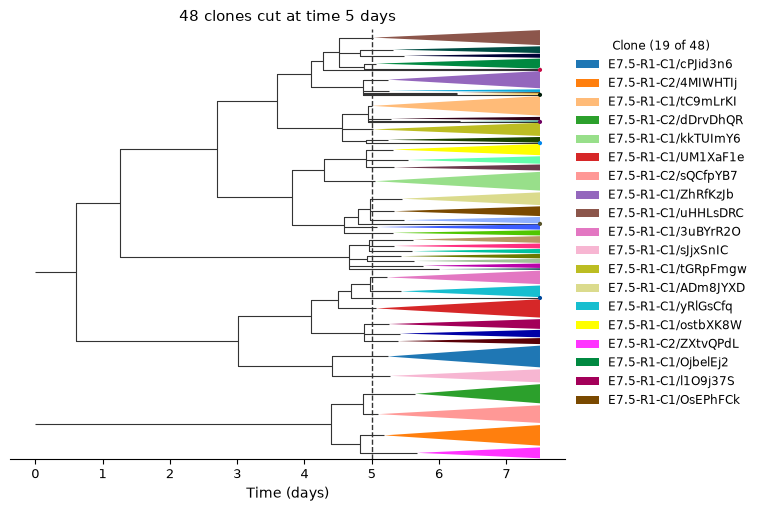

Started: 2026-11-12T17:21:55.624170Z | Wall time: 11.600 s

In [12]:
# Draw the trees with the clones of the cut at E5.0.
ds.plots.phylogeny(cuts[5.0])

Each wedge is one clone of two or more cells, drawn from the last common ancestor of its cells to day 7.5, and the legend names the largest clones by their tree and the name of each clone's root node in the authors' tree files, such as `E7.5-R1-C1/cPJid3n6`. The trees branch only a few times before day 4, and most of their branching before the cut falls between days 4 and 5, so the cut at day 5 already crosses 48 lineages.

## Measure coupling at each cut

`clones.coupling` measures how much two cell types share clones with CoSpar's default measure [@Wang_2022], which [lineage tracing](lineage_tracing.ipynb#find-the-fates-that-share-clones) defines. It then measures the coupling again on cell types shuffled among the cells with a clone, which keeps each clone's size and each type's size, and reports each pair's z-score: the coupling's distance from the null mean, the mean of the shuffled couplings, in null standard deviations. Measure the eight cell types of 10 or more donor cells, leaving out three primordial germ cells and one prechordal plate cell.

In [13]:
# Keep the cell types of at least 10 donor cells.
type_sizes = cell_types[cell_types != "host"].value_counts()
measured_types = type_sizes.index[type_sizes >= 10]
ds.cells.insert("in_measured_types", cell_types.isin(measured_types), overwrite=True)
measured_cells = ds.snapshot_cell_selection("in_measured_types")

# Measure the coupling of every pair of these cell types at each cut.
couplings = {
    time: ds.clones.coupling(
        clones, group_by="cell_type", cell_selection=measured_cells
    )
    for time, clones in cuts.items()
}

# Collect each pair's coupling, the mean of its shuffled couplings and its
# z-score at each cut, one column per cut.
by_cut = {
    value: pd.DataFrame(
        {
            f"E{time}": coupling.pairs.set_index(["group_1", "group_2"])[value]
            for time, coupling in couplings.items()
        }
    )
    for value in ("coupling", "null_mean", "z_score")
}

# List the five pairs whose z-score is highest at any cut.
z_scores = by_cut["z_score"]
z_scores.loc[z_scores.max(axis=1).nlargest(5).index].round(1)

E5.0  E5.5  E6.0  E6.5  \
group_1                 group_2                                                
Extraembryonic mesoderm Hematoendothelial progenitor   0.0   1.0   3.3   3.9   
Epiblast                Primitive streak               1.6   1.1   2.7   3.6   
                        Rostral ectoderm               0.1   0.5   1.7   1.2   
Definitive endoderm     Notochord                     -1.2  -0.3   1.0  -0.4   
Nascent mesoderm        Primitive streak              -1.0  -0.3  -0.2  -1.0   

                                                      E7.0  
group_1                 group_2                             
Extraembryonic mesoderm Hematoendothelial progenitor   2.2  
Epiblast                Primitive streak               1.5  
                        Rostral ectoderm               1.0  
Definitive endoderm     Notochord                     -0.3  
Nascent mesoderm        Primitive streak               0.8

Started: 2026-11-12T17:22:07.228765Z | Wall time: 3.646 s

No pair stands out at E5.0, where the highest z-score is 1.6. At E6.0 and E6.5 the extraembryonic mesoderm couples with the hematoendothelial progenitors, and the epiblast with the primitive streak, 2.7 to 3.9 standard deviations above the mean of their shuffles. Plotting the coupling and the z-score of each pair across the cuts shows why the cuts are compared by z-score.

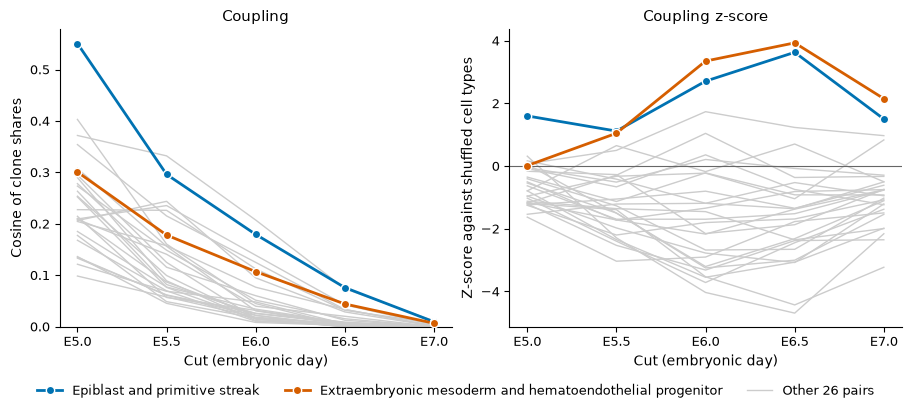

,Median coupling,Median shuffled mean,"Pairs above their shuffled mean, of 28"
Cut,,,
E5.0,0.22,0.30,6
E5.5,0.11,0.15,4
E6.0,0.03,0.06,6
E6.5,0.01,0.02,4
E7.0,0.00,0.00,4


Started: 2026-11-12T17:22:10.878282Z | Wall time: 0.439 s

In [14]:
# Color the two pairs whose z-scores peak highest, and draw the other pairs in gray.
highlights = dict(
    zip(z_scores.max(axis=1).nlargest(2).index, ["#D55E00", "#0072B2"], strict=True)
)
days = list(cuts)

# Follow every pair across the cuts, by its coupling and by its z-score.
with theme_context("notebook"):
    figure, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    for axis, value in zip(axes, ("coupling", "z_score"), strict=True):
        for pair, row in by_cut[value].iterrows():
            if pair in highlights:
                axis.plot(
                    days,
                    row,
                    color=highlights[pair],
                    linewidth=2,
                    marker="o",
                    markeredgecolor="white",
                    zorder=3,
                    label=f"{pair[0]} and {pair[1].lower()}",
                )
            else:
                axis.plot(days, row, color="0.8", linewidth=1, zorder=1)
        axis.set_xticks(days, [f"E{day}" for day in days])
        axis.set_xlabel("Cut (embryonic day)")

    # Name the panels, and mark the mean of the shuffled couplings, a z-score of 0.
    axes[0].set(title="Coupling", ylabel="Cosine of clone shares", ylim=(0, None))
    axes[1].axhline(0, color="0.4", linewidth=0.8, zorder=2)
    axes[1].set(title="Coupling z-score", ylabel="Z-score against shuffled cell types")
    others = f"Other {len(z_scores) - len(highlights)} pairs"
    axes[1].plot([], [], color="0.8", linewidth=1, label=others)
    figure.legend(
        *axes[1].get_legend_handles_labels(),
        loc="outside lower center",
        ncols=3,
        frameon=False,
    )
    plt.show()

# Compare the couplings at each cut with the means of their shuffles, and count
# the pairs that couple above their shuffles.
pd.DataFrame(
    {
        "Median coupling": by_cut["coupling"].median(),
        "Median shuffled mean": by_cut["null_mean"].median(),
        f"Pairs above their shuffled mean, of {len(z_scores)}": (
            by_cut["z_score"] > 0
        ).sum(),
    }
).rename_axis("Cut").round(2)

The coupling of every pair falls toward 0 at later cuts because the clones shrink: the clones of two or more cells hold 1,025 cells at E5.0 and 163 at E7.0. Shuffling keeps each clone's size, so the shuffled couplings fall as the clones shrink: from E5.0 to E7.0 the median coupling of the 28 pairs drops from 0.22 to 0.00, and the median of their shuffled means from 0.30 to 0.00. The z-score, which compares each cut with its own shuffles, is therefore the value to compare across cuts. The two highlighted pairs peak at E6.5 and fall back at E7.0, to 2.2 and 1.5, when only 78 clones hold two or more cells.

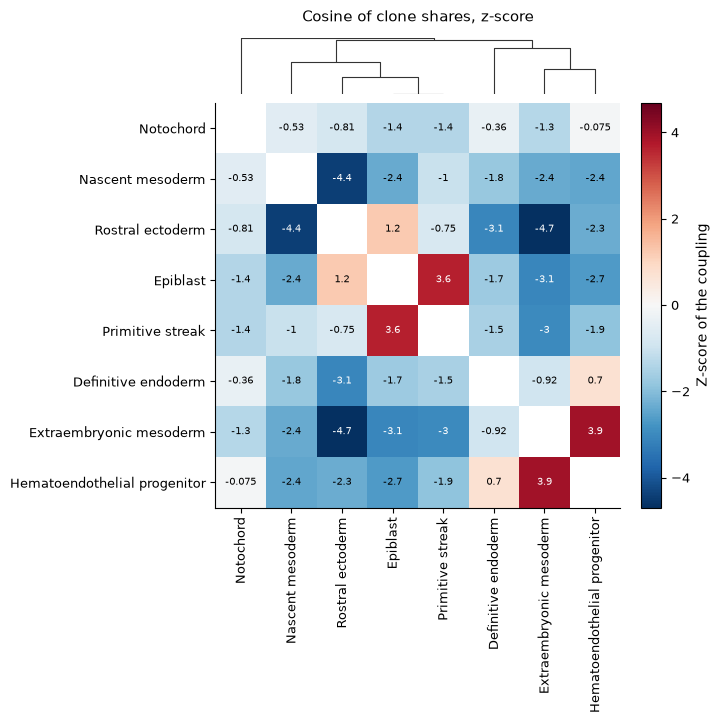

Started: 2026-11-12T17:22:11.323271Z | Wall time: 0.603 s

In [15]:
# Draw the z-scores of every pair at E6.5, with the cell types ordered by
# average linkage on their coupling.
ds.plots.clone_coupling(couplings[6.5], value="z_score")

At E6.5 the dendrogram, which average linkage builds from the couplings rather than their z-scores, joins the epiblast with the primitive streak and the rostral ectoderm, and the extraembryonic mesoderm with the hematoendothelial progenitors, which give the first blood and vessels. The rostral ectoderm shares far fewer clones with the mesoderm than shuffled labels would: its coupling with the extraembryonic and with the nascent mesoderm lies more than 4 standard deviations below the mean of the shuffles.

All but four pairs sit below 0 at E6.5, and at every cut only 4 to 6 of the 28 pairs couple above their shuffled mean. Shuffled labels spread each cell type over the clones in proportion to the clones' sizes, while real clones favor some cell types over others: at E6.5 the clones of two or more cells hold 1.7 cell types on average. The pairs that share clones then rise above 0 and most other pairs fall below 0, so read the order of the z-scores more than their sign.

Cutting the timed trees every half day turns one embryo into a time course of clones. From E5.0 to E6.5 the clones of two or more cells narrow from 5.3 cell types on average to 1.7, and two pairs stand out: the extraembryonic mesoderm with the hematoendothelial progenitors and the epiblast with the primitive streak still shared ancestors alive at E6.5, while the rostral ectoderm had separated from the nascent and extraembryonic mesoderm.

## Analyze your own recorder

- To analyze your own recorder, export its characters as above, build trees with Cassiopeia or LAML, and import them with `clones.import_phylogeny`. Trees whose branch lengths are not times take `time_unit=None` and are cut at a number of branchings below each root with `phylogeny_clones(phylogeny, depth=...)`.
- Without trees, `clones.allele_clones` links the cells that share a rare allele into clones, with DARLIN's allele-frequency threshold (`method="graph"`) or CARLIN's test of whether an allele arose more than once (`method="p_clonal"`).
- With clones sampled at several time points, [lineage tracing](lineage_tracing.ipynb) labels early cells by the fates that their clones took and tests a fate map against them.
- The [clones API reference](/api/clones.html) lists the recorder formats that `import_alleles` reads, from DARLIN to DNA Typewriter, and every clone summary that reads these clones.